# Unemployment in India | The COVID-19 Shock, Beyond the Headline

> **A human-centred data science investigation**  
> From raw monthly estimates to evidence that can inform employment policy.

This notebook asks three questions:
1. **What changed?** How did unemployment move before and during the COVID-19 disruption?
2. **Who was affected differently?** Did patterns vary across states and rural/urban areas?
3. **What should decision-makers consider?** What do the trends suggest—and what can this dataset not prove?

The analysis uses both supplied CSV files, but keeps them separate because one is **state × rural/urban area** data and the other is **state-level** data. Combining them as if they were identical observations would double-count overlapping months and mix different levels of geography.

## 1. Set the scene

The dataset is not a complete census of every worker. Its columns are estimates: unemployment rate, estimated employed people, and labour-force participation rate. We will be careful to distinguish **what the data shows** from **what we infer**.

**COVID period definition:** March 2020 onward. February 2020 and earlier are treated as the pre-COVID comparison window. This is a descriptive cut, not a causal experiment.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE = Path.cwd()
if not (BASE / "Unemployment in India.csv").exists():
    # Also supports running from the parent directory after extracting archive.zip.
    BASE = BASE / "unemployment_project"

RATE = "Estimated Unemployment Rate (%)"
EMP = "Estimated Employed"
PART = "Estimated Labour Participation Rate (%)"

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
NAVY, TEAL, CORAL, GOLD = "#14213D", "#2A9D8F", "#E76F51", "#E9C46A"
plt.rcParams.update({"figure.facecolor":"#F7F9FC", "axes.facecolor":"#F7F9FC",
                     "axes.titleweight":"bold", "font.family":"DejaVu Sans"})

## 2. Data quality: clean first, analyse second

The first CSV includes blank trailing records and repeated blank rows. These are removed transparently. Whitespace is stripped from column names and categories, dates are parsed explicitly, and numeric columns are coerced to numeric types.

**Important:** the two files have different structures and coverage. We do not concatenate them. Each gets its own cleaned table and trend line.

In [2]:
def load_and_clean(path, source_name):
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    for col in ["Region", "Frequency", "Area", "Region.1"]:
        if col in df:
            df[col] = df[col].astype("string").str.strip()
    df["Date"] = pd.to_datetime(df["Date"].astype(str).str.strip(),
                                dayfirst=True, errors="coerce")
    for col in [RATE, EMP, PART]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    raw_rows = len(df)
    df = df.dropna(subset=["Region","Date",RATE,EMP,PART]).drop_duplicates().copy()
    df["Source"] = source_name
    df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp("M")
    # Reconstruct an implied unemployed count from the reported rate and employed estimate.
    df["Estimated Unemployed (derived)"] = df[EMP] * df[RATE] / (100-df[RATE]).replace(0,np.nan)
    df["Estimated Labour Force (derived)"] = df[EMP] + df["Estimated Unemployed (derived)"]
    print(f"{source_name}: {raw_rows:,} raw -> {len(df):,} retained "
          f"({raw_rows-len(df):,} removed)")
    return df

area = load_and_clean(BASE/"Unemployment in India.csv", "Area-level")
state = load_and_clean(BASE/"Unemployment_Rate_upto_11_2020.csv", "State-level")

display(area.head())
display(state.head())

Area-level: 768 raw -> 740 retained (28 removed)
State-level: 267 raw -> 267 retained (0 removed)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Source,Month,Estimated Unemployed (derived),Estimated Labour Force (derived)
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,Area-level,2019-05-31,454560.014011,1.245370e+07
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,Area-level,2019-06-30,369834.317174,1.212572e+07
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,Area-level,2019-07-31,470910.662338,1.255762e+07
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,Area-level,2019-08-31,421891.815887,1.270758e+07
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,Area-level,2019-09-30,668221.654962,1.292498e+07


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude,Source,Month,Estimated Unemployed (derived),Estimated Labour Force (derived)
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74,State-level,2020-01-31,9.644809e+05,1.760002e+07
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74,State-level,2020-02-29,1.024330e+06,1.756998e+07
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74,State-level,2020-03-31,9.760337e+05,1.685723e+07
3,Andhra Pradesh,2020-04-30,M,20.51,11336911,33.10,South,15.9129,79.74,State-level,2020-04-30,2.925148e+06,1.426206e+07
4,Andhra Pradesh,2020-05-31,M,17.43,12988845,36.46,South,15.9129,79.74,State-level,2020-05-31,2.741862e+06,1.573071e+07


In [3]:
quality = pd.DataFrame({
    "Dataset": ["Area-level", "State-level"],
    "Rows after cleaning": [len(area), len(state)],
    "Regions": [area.Region.nunique(), state.Region.nunique()],
    "Start": [area.Date.min().date(), state.Date.min().date()],
    "End": [area.Date.max().date(), state.Date.max().date()],
    "Missing cells": [int(area.isna().sum().sum()), int(state.isna().sum().sum())],
    "Invalid unemployment rates": [
        int((~area[RATE].between(0,100)).sum()),
        int((~state[RATE].between(0,100)).sum())
    ]
})
display(quality)

,Dataset,Rows after cleaning,Regions,Start,End,Missing cells,Invalid unemployment rates
0,Area-level,740,28,2019-05-31,2020-06-30,0,0
1,State-level,267,27,2020-01-31,2020-10-31,0,0


## 3. A fairer national trend estimate

A simple average gives a small state/area the same influence as a large one. To avoid that, we derive an approximate unemployed count for each row:

`unemployed ≈ employed × rate / (100 − rate)`

Then monthly rates are reconstructed from summed employed and implied unemployed estimates. This is a **derived approximation**, not an official national series. It assumes the reported rate and employed estimate are internally compatible.

In [4]:
def weighted_monthly_rate(df):
    m = df.groupby("Month").agg(
        employed=(EMP,"sum"),
        unemployed=("Estimated Unemployed (derived)","sum"),
        labour_force=("Estimated Labour Force (derived)","sum")
    )
    m["unemployment_rate"] = 100*m.unemployed/m.labour_force
    return m.reset_index()

area_monthly = weighted_monthly_rate(area)
state_monthly = weighted_monthly_rate(state)
display(area_monthly.round(2))

,Month,employed,unemployed,labour_force,unemployment_rate
0,2019-05-31,400148016.0,30294219.46,4.304422e+08,7.04
1,2019-06-30,397366645.0,33980930.54,4.313476e+08,7.88
2,2019-07-31,399838967.0,31797632.38,4.316366e+08,7.37
3,2019-08-31,399610205.0,35129543.30,4.347397e+08,8.08
4,2019-09-30,402452126.0,30644362.33,4.330965e+08,7.08
5,2019-10-31,401411032.0,35407584.64,4.368186e+08,8.11
6,2019-11-30,400051335.0,31252072.79,4.313034e+08,7.25
7,2019-12-31,391001555.0,32737712.24,4.237393e+08,7.73
8,2020-01-31,406899254.0,31737358.75,4.386366e+08,7.24
9,2020-02-29,403011803.0,33986836.86,4.369986e+08,7.78


## 4. The COVID-19 shock: what changed?

The area-level dataset shows a sharp increase in the derived monthly estimate in April 2020, followed by a partial easing in May and June. The independent state-level file shows a similar April spike and extends the story through October 2020, where the estimate moves closer to its early-2020 level.

This is a strong descriptive signal of disruption and recovery. It does **not**, by itself, prove that COVID-19 was the only cause: the dataset has no control group or counterfactual.

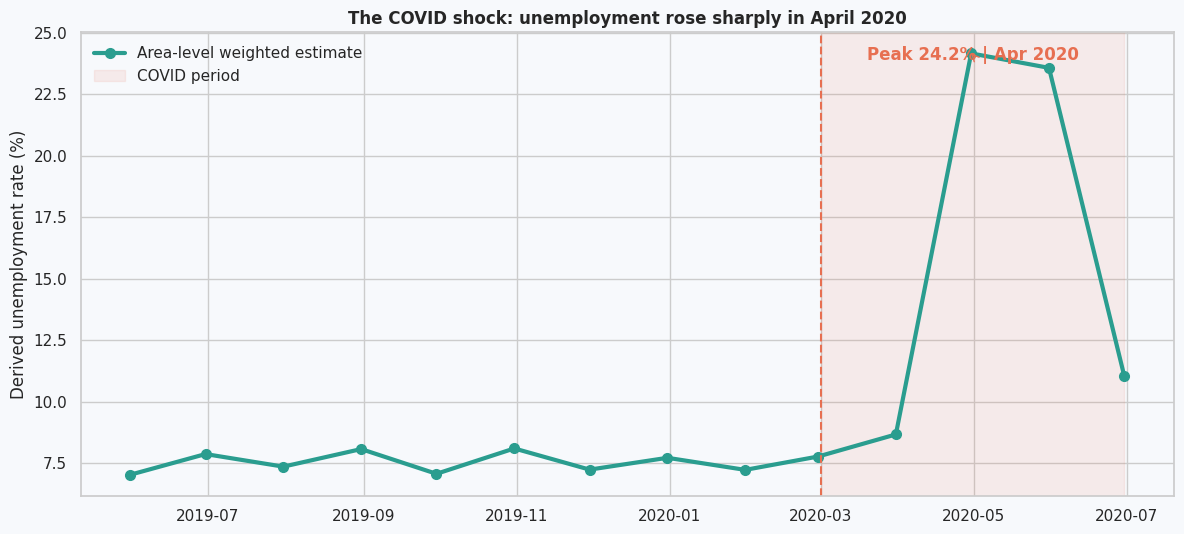

Pre-COVID mean (May 2019–Feb 2020): 7.55%
COVID-window mean (Mar–Jun 2020): 16.86%
Difference: +9.31 percentage points


In [5]:
fig, ax = plt.subplots(figsize=(12,5.5))
ax.plot(area_monthly.Month, area_monthly.unemployment_rate, color=TEAL,
        marker="o", linewidth=3, markersize=7, label="Area-level weighted estimate")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-06-30"),
           color=CORAL, alpha=.10, label="COVID period")
ax.axvline(pd.Timestamp("2020-03-01"), color=CORAL, linestyle="--")
peak = area_monthly.loc[area_monthly.unemployment_rate.idxmax()]
ax.annotate(f"Peak {peak.unemployment_rate:.1f}% | {peak.Month:%b %Y}",
            (peak.Month,peak.unemployment_rate), xytext=(-75,-5),
            textcoords="offset points", color=CORAL, fontweight="bold",
            arrowprops=dict(arrowstyle="->",color=CORAL))
ax.set(title="The COVID shock: unemployment rose sharply in April 2020",
       ylabel="Derived unemployment rate (%)", xlabel="")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

pre = area_monthly.loc[area_monthly.Month <= "2020-02-29","unemployment_rate"].mean()
covid = area_monthly.loc[area_monthly.Month.between("2020-03-31","2020-06-30"),
                         "unemployment_rate"].mean()
print(f"Pre-COVID mean (May 2019–Feb 2020): {pre:.2f}%")
print(f"COVID-window mean (Mar–Jun 2020): {covid:.2f}%")
print(f"Difference: {covid-pre:+.2f} percentage points")

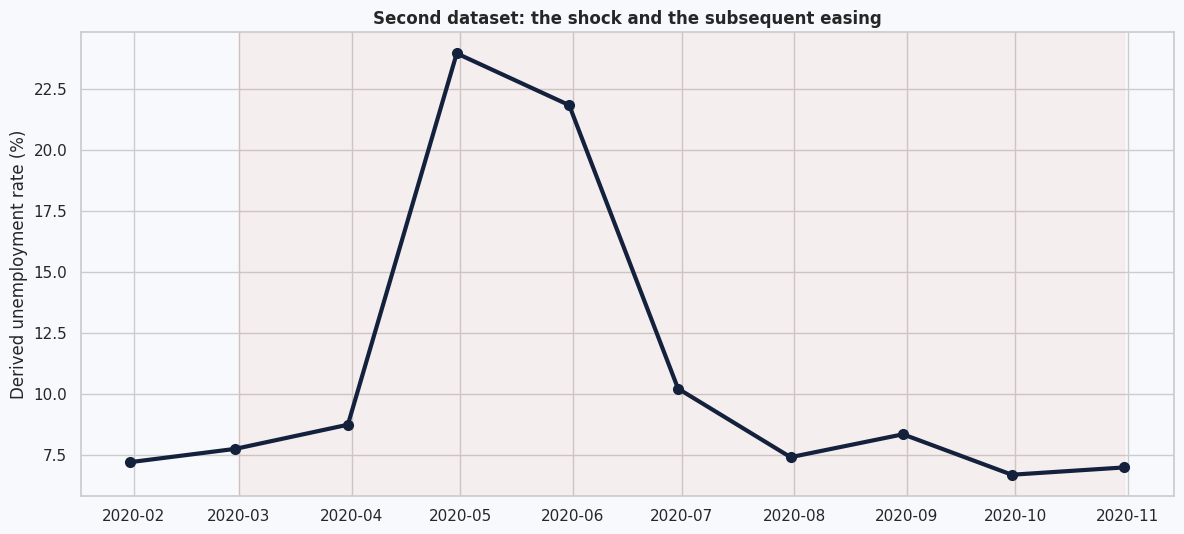

In [6]:
fig, ax = plt.subplots(figsize=(12,5.5))
ax.plot(state_monthly.Month,state_monthly.unemployment_rate,color=NAVY,
        marker="o",linewidth=3,markersize=7)
ax.axvspan(pd.Timestamp("2020-03-01"),pd.Timestamp("2020-10-31"),
           color=CORAL,alpha=.08)
ax.set(title="Second dataset: the shock and the subsequent easing",
       ylabel="Derived unemployment rate (%)",xlabel="")
plt.tight_layout()
plt.show()

## 5. Not everyone experiences the labour market in the same way

The area-level file lets us compare rural and urban observations. The chart below uses the mean of the observed area-level rates over the available period. It is descriptive—not population-weighted—and should not be interpreted as a precise rural/urban national estimate.

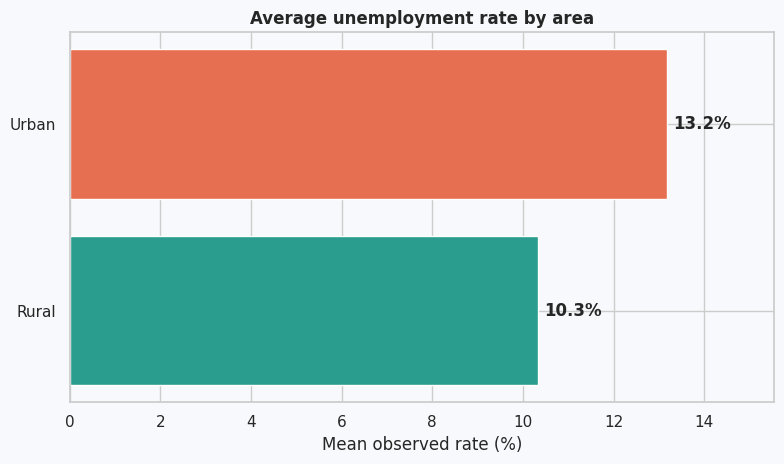

,Mean observed unemployment rate (%)
Area,
Rural,10.32
Urban,13.17


In [7]:
area_means = area.groupby("Area")[RATE].mean().sort_values()
fig, ax = plt.subplots(figsize=(8,4.8))
bars=ax.barh(area_means.index,area_means.values,
             color=[TEAL if x=="Rural" else CORAL for x in area_means.index])
for bar,val in zip(bars,area_means.values):
    ax.text(val+.15,bar.get_y()+bar.get_height()/2,f"{val:.1f}%",va="center",fontweight="bold")
ax.set(title="Average unemployment rate by area",xlabel="Mean observed rate (%)",ylabel="")
ax.set_xlim(0,max(area_means.values)*1.18)
plt.tight_layout()
plt.show()
display(area_means.rename("Mean observed unemployment rate (%)").to_frame().round(2))

## 6. State-level hotspots and unequal recovery

April 2020 is used as a common stress point. The top states are shown to highlight where pressure was most pronounced in this dataset. These are not rankings of long-run economic performance.

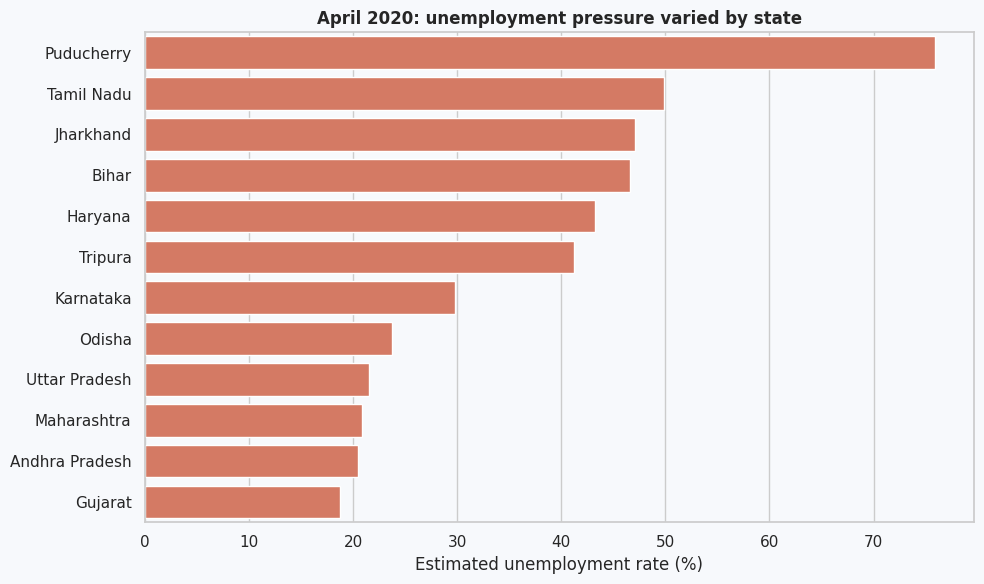

In [8]:
april = state[state.Month.eq(pd.Timestamp("2020-04-30"))].nlargest(12,RATE)
fig,ax=plt.subplots(figsize=(10,6))
sns.barplot(data=april,x=RATE,y="Region",color=CORAL,ax=ax)
ax.set(title="April 2020: unemployment pressure varied by state",
       xlabel="Estimated unemployment rate (%)",ylabel="")
plt.tight_layout()
plt.show()

In [9]:
sp = state.assign(Period=np.where(state.Date<"2020-03-01","Pre-COVID","COVID period"))
pivot=sp.groupby(["Region","Period"])[RATE].mean().unstack()
if {"Pre-COVID","COVID period"}.issubset(pivot.columns):
    pivot["Change (percentage points)"]=pivot["COVID period"]-pivot["Pre-COVID"]
    display(pivot.sort_values("Change (percentage points)",ascending=False).head(12).round(2))

Period,COVID period,Pre-COVID,Change (percentage points)
Region,,,
Puducherry,22.14,1.17,20.96
Tamil Nadu,14.78,1.83,12.95
Bihar,21.73,10.45,11.28
Jharkhand,21.62,11.23,10.39
Goa,13.75,5.85,7.90
Uttarakhand,12.64,5.24,7.40
Karnataka,8.78,3.24,5.54
Haryana,28.58,23.06,5.53
West Bengal,11.26,5.93,5.33


## 7. Labour-force participation: a second signal

Unemployment alone does not tell the whole story. If people stop looking for work, they may leave the labour force and no longer count as unemployed. Participation therefore provides useful context alongside the unemployment rate.

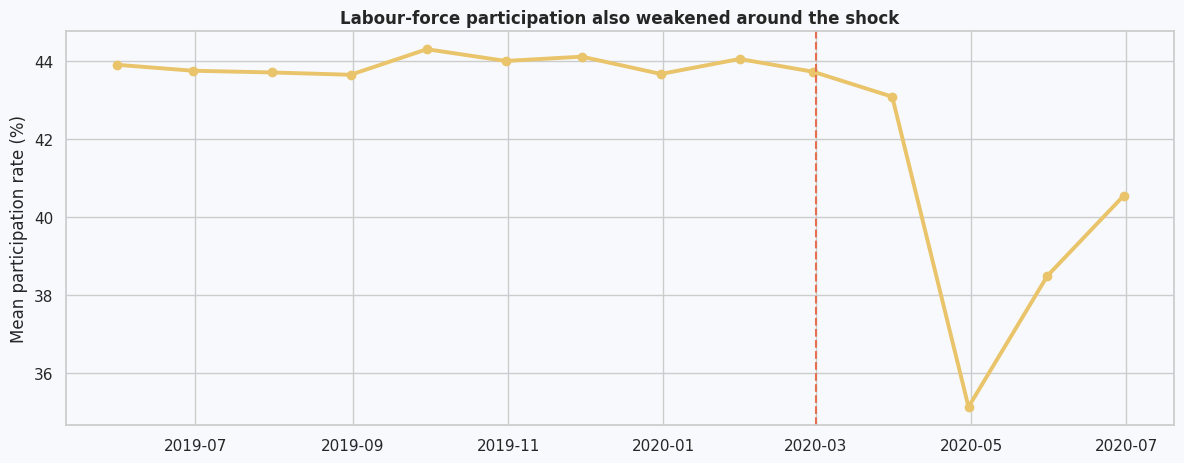

In [10]:
participation=area.groupby("Month")[PART].mean().reset_index()
fig,ax=plt.subplots(figsize=(12,4.8))
ax.plot(participation.Month,participation[PART],color=GOLD,marker="o",linewidth=2.8)
ax.axvline(pd.Timestamp("2020-03-01"),color=CORAL,linestyle="--")
ax.set(title="Labour-force participation also weakened around the shock",
       ylabel="Mean participation rate (%)",xlabel="")
plt.tight_layout()
plt.show()

## 8. Seasonality: what can and cannot be claimed

The area-level dataset covers only **14 months** (May 2019–June 2020). That is barely more than one annual cycle, so it is not enough to establish a recurring seasonal pattern. Monthly variation is visible, but calling it seasonality would overstate the evidence.

A stronger seasonal study would need at least 3–5 years of monthly observations, consistent definitions, and a decomposition that separates trend, seasonality, and irregular shocks.

## 9. Policy implications: turn the chart into action

| Evidence in this dataset | Policy response worth evaluating |
|---|---|
| A sharp April 2020 spike | Rapid-response income support and temporary wage subsidies during large shocks |
| State-level differences | State-specific employment dashboards and targeted relief rather than one uniform allocation |
| Rural/urban differences | Separate rural livelihood support and urban informal-worker protection |
| Participation also weakened | Track job-search participation and labour-force exit, not unemployment alone |
| Recovery after the peak | Monitor job quality, hours, wages, and sustained employment—not only the headline rate |

These are policy directions to investigate, not causal conclusions proven by this dataset.

## 10. Limitations and responsible interpretation

- The files contain estimates, not individual-level records.
- The first file is area-level (state × rural/urban); the second is state-level. Their overlapping periods and different granularity mean they must not be pooled as duplicate observations.
- The national monthly rate shown here is reconstructed from reported employment and unemployment rates. It is an approximation and depends on the formula assumption.
- The COVID period is a descriptive time split. Without a counterfactual, this analysis cannot isolate COVID's causal effect from other concurrent changes.
- Fourteen months cannot establish reliable annual seasonality.
- The data ends in October 2020; it cannot describe India's current labour market.

## Final takeaway

**The clearest signal is a sudden labour-market shock in April 2020, followed by easing in the months that follow.** But the human story is not one number: impacts differed by state and area, and participation also matters. Good policy should therefore be fast during shocks, targeted to local conditions, and measured by sustained, decent work—not just a falling unemployment rate.